# Mock maker interface

This notebook provides the interface with the `horizon` mock generator, producing mock luminosity and angular diameter distances as measured from QSO. It is built on the standard sirens mock generator used to produce the results presented in <a href="www.arxiv.org/abs/2007.14335">2007.14335</a>.

## Import packages

In [1]:
from tools.theory import Theory
from tools.qso_mock import QSOMockGenerator

In [2]:
import numpy as np
from scipy.interpolate import interp1d
from scipy.integrate import trapezoid
import matplotlib.pyplot as plt

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif"
})

# speed of light
clight = 299792.458

## Set the  observational specifications
Here we can set:
* `n_QSO`: the number of observed events (i.e. the size of our mock dataset).
* `z_min`, `z_max`: the minimum and maximum redshifts.

In [3]:
specifications = {'n_QSO': 200, 
                  'z_min': 0.4, 
                  'z_max': 2} 

## Set fiducial cosmology
Here we set $\Omega_m$ and $H_0$ and the model for the DDR violation in the luminosity distance.

The available options for the `EM_deviation` are:
#### M1
$\eta = 1 + \alpha$

#### M2
$\eta = 1 + \alpha + \beta z$

#### M3
$\eta = (1+z)^\alpha$

In [4]:
params = {'Omegam': 0.314,
          'H0': 67.36}

# model for DDR violation
DDR_violation = {'model': 'M1', 
                 'alpha': 0.1,
                 'beta':0}

zspecs = np.linspace(specifications['z_min'], specifications['z_max'], 1000)

## Set where the mock data file will be saved
If the `mock_data` directory does not exist locally, you need to create it before the mock can be saved.

In [5]:
outpath = 'mock_data/'+DDR_violation['model']+'alpha'+str(DDR_violation['alpha'])+'beta'+str(DDR_violation['beta'])+'nQSO'+str(specifications['n_QSO'])

In [6]:
print(outpath)

mock_data/M1alpha0.1beta0nQSO200


## Compute relevant cosmological quantities
Here we compute the various distances etc.

In [7]:
zcosmo = np.linspace(0, specifications['z_max'], 1000)

# H(z)
Hubble = interp1d(zcosmo, params['H0']*np.sqrt(params['Omegam']*(1 + zcosmo)**3 + (1 - params['Omegam'])), kind='cubic')

# distances
com = []
for zi in zspecs:
    zint  = np.linspace(0, zi, 100)
    dz    = (zi - 0.)/100
    com.append(clight*trapezoid(1/Hubble(zint),zint,dx=dz))

comoving_distance = interp1d(zspecs, com, kind='cubic')
angular_distance  = interp1d(zspecs, com/(1+zspecs), kind='cubic')
hubble_mpc = interp1d(zcosmo, Hubble(zcosmo)/clight, kind='cubic')

# fiducial luminosity distance when DDR is not violated
luminosity_LCDM = interp1d(zspecs, (1+zspecs)*com, kind='cubic')

In [8]:
# set up theory class
TH = Theory(zspecs, comoving_distance, angular_distance, Hubble, 
            params['Omegam'], params['H0'], 
            DDR_violation['alpha'], DDR_violation['beta'], DDR_violation['model'])

# retrieve luminosity distance in the presence of DDR violation
# note we only consider DDR violation in the luminosity sector
# angular breaking may be possible, cite Felicitas' work: 2504.01750
luminosity_EM = TH.EMlumdist()

## Run the mock maker

In [9]:
QSO_mock = QSOMockGenerator(
    params, 
    specifications, 
    zspecs, 
    outpath, 
    dl_func=luminosity_EM, 
    da_func=angular_distance
)

Generating synchronized QSO mock datasets.
Validated Luminosity residuals: mu=0.0071, sigma=0.9959
Validated Angular residuals: mu=-0.0012, sigma=0.9929
Datasets saved to mock_data/M1alpha0.1beta0nQSO200_dl/da_dataset.txt


## Plot the mock data

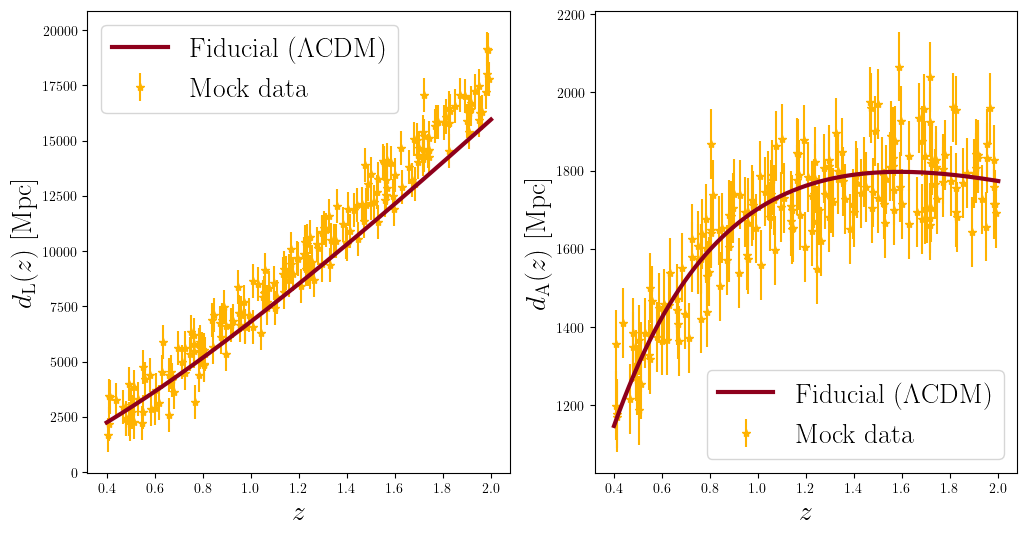

In [10]:
# Retrieve the synchronized data using the updated mock() method
mock_data = QSO_mock.mock()

dl_data = {
    'z': mock_data['z'], 
    'value': mock_data['dl_value'], 
    'error': mock_data['dl_error']
}

da_data = {
    'z': mock_data['z'], 
    'value': mock_data['da_value'], 
    'error': mock_data['da_error']
}
fig, ax = plt.subplots(1,2, figsize=(12,6))

# mock data
ax[0].errorbar(dl_data['z'], dl_data['value'], yerr=dl_data['error'], 
               color='#FFB300', ls='', marker='*', label='Mock data', zorder = 0)

ax[1].errorbar(da_data['z'], da_data['value'], yerr=da_data['error'], 
               color='#FFB300', ls='', marker='*', label='Mock data', zorder = 0)

# fiducial cosmology
ax[0].plot(zspecs, luminosity_LCDM(zspecs), color='#8E001C',lw=3,label=r'Fiducial ($\Lambda$CDM)', zorder = 10)
ax[1].plot(zspecs, angular_distance(zspecs), color='#8E001C',lw=3,label=r'Fiducial ($\Lambda$CDM)', zorder = 10)

# labels
ax[0].set_xlabel(r'$z$',fontsize = 20)
ax[0].set_ylabel(r'$d_{\rm L}(z)$ [Mpc]',fontsize = 20)
ax[0].legend(loc='best',fontsize = 20)

ax[1].set_xlabel(r'$z$',fontsize = 20)
ax[1].set_ylabel(r'$d_{\rm A}(z)$ [Mpc]',fontsize = 20)
ax[1].legend(loc='best',fontsize = 20)

plt.show()

### Statistical checks

Check the Gaussianity of the mock data.

-----------------------------------REPORT ON QSO luminosity distance-----------------------------------
Number of outliers: 200
Fraction of data: 100.0%
Maximum distance from fiducial (in sigma): 24.846541808087796


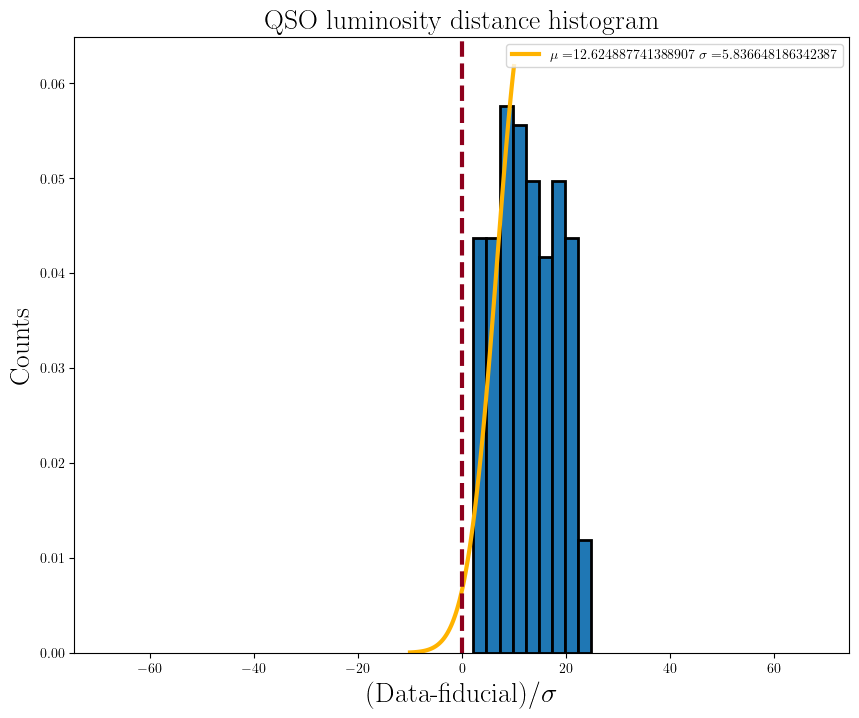

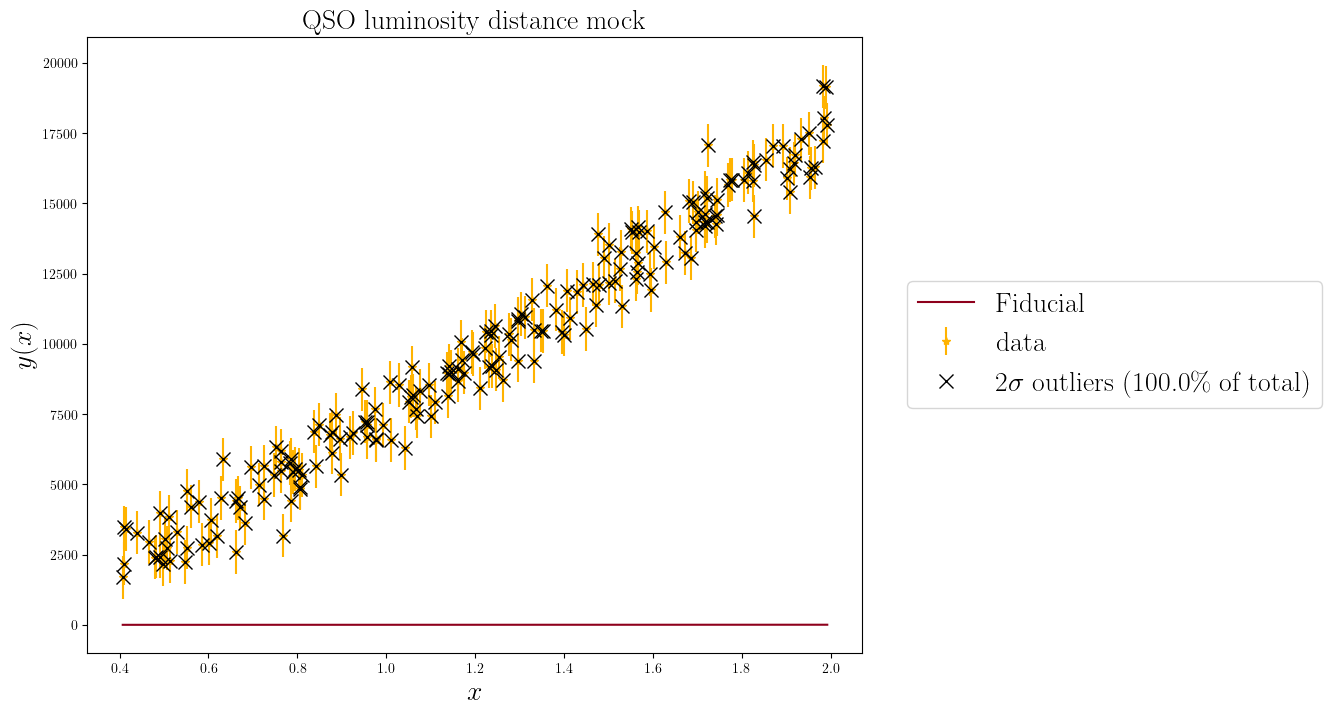

In [11]:
from tools.mockchecker import MockChecker

MockChecker(x = dl_data['z'], data = dl_data['value'], error = dl_data['error'],
            # fiducial = np.array([luminosity_LCDM(zi) for zi in dl_data['z']]),
            fiducial = np.array([luminosity_EM(zi) for zi in dl_data['z']]),
            threshold = 2, dataname='QSO luminosity distance');